# 04. Czujny kontra senny na naszych 8 kanałach: zbiór publiczny Cui i in.

Zadanie B2 z [`docs/zadania.md`](../../docs/zadania.md). Pytania:

1. Czy wskaźniki zmęczenia, które planujemy w Wachcie (alfa potyliczna, alfa ciemieniowa, theta czołowa, (theta+alfa)/beta, beta/(alfa+theta)), odróżniają stan **czujny** od **sennego** na **tych samych 8 elektrodach**, które ma BrainAccess MINI (F3, F4, C3, C4, P3, P4, O1, O2)?
2. Jak to wygląda **u każdej osoby osobno** (AUC na osobę)?
3. **Kalibracja osobista czy jeden próg dla wszystkich?** Porównujemy: (a) model/próg nauczony na innych osobach bez normalizacji, (b) to samo z normalizacją do kalibracji danej osoby, (c) model uczony na tej samej osobie (górna, optymistyczna granica).

**Zbiór:** *EEG driver drowsiness dataset*, J. Cui, figshare, [doi:10.6084/m9.figshare.14273687.v3](https://doi.org/10.6084/m9.figshare.14273687.v3), licencja **CC BY 4.0**. To wycinek zbioru Cao i in. 2019 (*Multi-channel EEG recordings during a sustained-attention driving task*, Scientific Data 6:1), opisany w pracy Cui i in. 2021 (*Methods*, [doi:10.1016/j.ymeth.2021.04.017](https://doi.org/10.1016/j.ymeth.2021.04.017), preprint [arXiv:2106.00613](https://arxiv.org/abs/2106.00613)).

Notebook sam pobiera plik (172 MB) do katalogu poza repo: `/content/data` w Colabie, a lokalnie `~/.cache/wachta-eeg`. **Nic ze zbioru nie trafia do repo**, zapisujemy tylko jeden wykres do `docs/img/`.

In [1]:
%pip install -q scipy scikit-learn pandas matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /tmp/claude-0/work/v/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.signal import welch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.precision", 2)

CACHE = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
CACHE.mkdir(parents=True, exist_ok=True)
URL = "https://ndownloader.figshare.com/files/30707285"   # dataset.mat, article 14273687 v3
MD5 = "ead0e57bc91cc09630db55129dc98964"                   # from the figshare API
MAT = CACHE / "cui2021-driver-drowsiness-dataset.mat"

if not MAT.exists():
    print("downloading", URL, "->", MAT)
    urllib.request.urlretrieve(URL, MAT)
h = hashlib.md5()
with open(MAT, "rb") as fh:
    for chunk in iter(lambda: fh.read(1 << 20), b""):
        h.update(chunk)
assert h.hexdigest() == MD5, "MD5 mismatch, delete the file and download again"
print(MAT, f"{MAT.stat().st_size / 1e6:.1f} MB, md5 ok")

# Channel order is not stored in the .mat file. It comes from the authors' code
# (LeaveOneOut_acc.py and VisualizationTech.py in github.com/cuijiancorbin/A-Compact-and-Interpretable-...).
ALL_CH = ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "FT7", "FC3", "FCZ", "FC4", "FT8", "T3", "C3", "Cz",
          "C4", "T4", "TP7", "CP3", "CPz", "CP4", "TP8", "T5", "P3", "PZ", "P4", "T6", "O1", "Oz", "O2"]
OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 128            # Hz, set by Cui et al. (downsampled from 500 Hz)
SEG_S = 2.0         # Welch segment = our 2 s window; each 3 s sample gives 2 half-overlapping segments
REJECT_UV = 300     # same peak-to-peak rule as our pipeline
BANDS = {"theta": (4, 7), "alpha": (8, 12), "beta": (13, 30)}
SEED = 0

/content/data/cui2021-driver-drowsiness-dataset.mat 180.8 MB, md5 ok


## 1. Co jest w pliku (sprawdzone, nie założone)

Plik to MATLAB 5 (`scipy.io.loadmat`) z trzema zmiennymi: `EEGsample` (próbki × kanały × punkty), `subindex` (numer osoby 1–11), `substate` (0 = czujny, 1 = senny). **Nazw kanałów w pliku nie ma.** Opis na figshare mówi „20x384” i jednocześnie „30 EEG channels”; faktyczny kształt jest niżej. Kolejność kanałów bierzemy z kodu autorów i sprawdzamy ją na danych: sąsiednie elektrody powinny być ze sobą najmocniej skorelowane.

In [3]:
m = sio.loadmat(MAT)
print(m["__header__"].decode())
X_all = m["EEGsample"].astype(np.float32)          # (n, 30, 384), µV
subj = m["subindex"].ravel().astype(int)
y = m["substate"].ravel().astype(int)
print("EEGsample", X_all.shape, "| duration per sample:", X_all.shape[2] / FS, "s at", FS, "Hz")
print("subjects:", np.unique(subj).size, "| samples:", len(y))
counts = pd.crosstab(subj, y).rename(columns={0: "alert", 1: "drowsy"})
counts.index.name = "subject"
print(counts.T.to_string())

missing = [c for c in OUR_CH if c not in ALL_CH]
idx = [ALL_CH.index(c) for c in OUR_CH]
print("our channels present:", [f"{c}->{i}" for c, i in zip(OUR_CH, idx)], "| missing:", missing or "none")

# sanity check of the channel order: 3 most correlated channels for each of ours
C = np.corrcoef(X_all.transpose(1, 0, 2).reshape(30, -1))
for c, i in zip(OUR_CH, idx):
    nb = np.argsort(-C[i])[1:4]
    print(f"  {c:3s} most correlated with:", ", ".join(f"{ALL_CH[j]} ({C[i, j]:.2f})" for j in nb))

# spectrum check: Nyquist 64 Hz, authors' 1-50 Hz FIR band-pass should be visible
f, p = welch(X_all[:, idx], FS, nperseg=256, axis=-1)
pm = 10 * np.log10(p.mean((0, 1)))
print("mean PSD [dB re µV²/Hz] at", {fr: round(float(pm[f == fr][0]), 1) for fr in (1, 4, 10, 30, 45, 50, 55, 60)})

# ordering: labels come as one alert block followed by one drowsy block per subject
print("label switches inside each subject:", {k: int((np.diff(y[subj == k]) != 0).sum()) for k in counts.index})

MATLAB 5.0 MAT-file, Platform: PCWIN64, Created on: Thu Dec 12 16:15:31 2019
EEGsample (2022, 30, 384) | duration per sample: 3.0 s at 128 Hz
subjects: 11 | samples: 2022
subject  1   2   3   4    5   6   7    8    9   10   11
col_0                                                  
alert    94  66  75  74  112  83  51  132  157  54  113
drowsy   94  66  75  74  112  83  51  132  157  54  113
our channels present: ['F3->3', 'F4->5', 'C3->13', 'C4->15', 'P3->23', 'P4->25', 'O1->27', 'O2->29'] | missing: none


  F3  most correlated with: FC3 (0.42), Fz (0.41), FCZ (0.40)
  F4  most correlated with: FC4 (0.44), Fz (0.43), FCZ (0.42)
  C3  most correlated with: FC3 (0.95), CP3 (0.93), Cz (0.88)
  C4  most correlated with: CP4 (0.93), FC4 (0.93), Cz (0.87)
  P3  most correlated with: CP3 (0.94), PZ (0.89), CPz (0.87)
  P4  most correlated with: CP4 (0.93), PZ (0.89), CPz (0.87)
  O1  most correlated with: Oz (0.91), O2 (0.84), T5 (0.79)
  O2  most correlated with: Oz (0.91), O1 (0.84), T6 (0.78)


mean PSD [dB re µV²/Hz] at {1: 14.3, 4: 6.2, 10: 9.3, 30: 0.9, 45: -1.3, 50: -3.9, 55: -61.0, 60: -64.2}
label switches inside each subject: {1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1}


Wnioski z komórki powyżej:

- **11 osób, 2022 okna po 3 s (384 punkty przy 128 Hz), 30 kanałów.** Każda osoba ma dokładnie tyle samo okien czujnych co sennych (od 51+51 do 157+157). Zbiór jest sztucznie zrównoważony przez autorów (patrz niżej).
- **Wszystkie 8 naszych kanałów jest w zbiorze** (F3, F4, C3, C4, P3, P4, O1, O2), brakujących nie ma. Kolejność z kodu autorów zgadza się z danymi: C3 koreluje najmocniej z FC3/CP3, O1 z Oz/O2 itd.
- Widmo spada gwałtownie powyżej 50 Hz, czyli widać filtr 1–50 Hz autorów zbioru Cao. Nasze pasma (4–30 Hz) leżą w środku, więc **nie przepróbkowujemy i nie filtrujemy dodatkowo**. Nasz pipeline filtruje 1–40 Hz przy 250 Hz; dla mocy w pasmach 4–30 Hz to bez znaczenia.
- **Kolejność okien:** w każdej osobie najpierw są wszystkie okna czujne, potem wszystkie senne. Nie ma znaczników czasu, więc nie wiemy, czy kolejność wewnątrz klasy jest chronologiczna.

Jak powstały etykiety (z pracy Cui i in. 2021, rozdz. 2B, sprawdzone w pełnym tekście):

| Krok | Kto | Co |
|---|---|---|
| Zadanie | Cao i in. | jazda w symulatorze VR, ok. 90 min po obiedzie, losowe zjazdy auta z pasa; trzeba skontrować kierownicą |
| Sprzęt | Cao i in. | czepek z 30 elektrodami **żelowymi Ag/AgCl**, referencja: dwa wyrostki sutkowate (A1/A2), 500 Hz |
| Obróbka | Cao i in. | FIR 1–50 Hz, ręczne usunięcie mrugnięć, usunięcie artefaktów ocznych i mięśniowych wtyczką AAR w EEGLAB |
| Okna | Cui i in. | przepróbkowanie do 128 Hz, **3 s tuż przed początkiem zjazdu z pasa** w każdej próbie |
| Etykieta | Cui i in. | **czas reakcji (RT)**: lokalny RT próby i globalny RT (średnia z 90 s). „alert-RT” = 5. percentyl RT w sesji. **Czujny**: oba RT < 1,5 × alert-RT; **senny**: oba > 2,5 × alert-RT; stany pośrednie wyrzucone |
| Selekcja | Cui i in. | sesje z ≥ 50 oknami każdej klasy; z kilku sesji osoby ta najbardziej zrównoważona; **klasę liczniejszą przycięto do mniej licznej, wybierając okna o najkrótszym (czujny) lub najdłuższym (senny) RT** |

Etykieta jest więc **behawioralna** (spowolnione reakcje), a nie oparta na EEG ani samoocenie. Ostatni krok wybiera skrajne przypadki, co **zawyża** rozdzielność klas względem realnej zmiany.

## 2. Cechy na okno

Dla każdego 3-sekundowego okna i każdego z 8 kanałów liczymy moc w pasmach theta 4–7, alfa 8–12, beta 13–30 Hz metodą Welcha z segmentem 2 s (jak nasze okno) i nakładką 1 s, więc jedno okno 3 s to średnia z dwóch segmentów 2 s. Moc w skali log10 (µV²).

Okna z amplitudą międzyszczytową > 300 µV na którymkolwiek z 8 kanałów odrzucamy (ta sama reguła co w naszym pipeline).

Wskaźniki (kierunek „oczekiwany przy senności” w nawiasie):

| Wskaźnik | Definicja | Oczekiwany kierunek |
|---|---|---|
| `alpha_occ` | log mocy alfa, średnia O1/O2 | rośnie |
| `alpha_par` | log mocy alfa, średnia P3/P4 | rośnie |
| `theta_front` | log mocy theta, średnia F3/F4 | rośnie |
| `ta_b` | log((theta+alfa)/beta), moce uśrednione po 8 kanałach | rośnie |
| `b_ta` | log(beta/(alfa+theta)), jak `engagement` w notebooku 03 | maleje |

AUC liczymy zawsze **w kierunku oczekiwanym**: AUC > 0,5 znaczy, że wskaźnik zmienia się tak, jak przewiduje literatura; AUC < 0,5 znaczy, że u tej osoby jest odwrotnie.

In [4]:
def band_features(X, fs=FS):
    # X: (n, 8, samples) in µV -> DataFrame of log band powers per channel + markers
    f, p = welch(X, fs, nperseg=int(SEG_S * fs), noverlap=int((SEG_S - 1) * fs), axis=-1)
    df_hz = f[1] - f[0]
    pw = {b: p[:, :, (f >= lo) & (f <= hi)].sum(-1) * df_hz for b, (lo, hi) in BANDS.items()}  # (n, 8), µV²
    d = pd.DataFrame({f"{b}_{c}": np.log10(pw[b][:, i]) for b in BANDS for i, c in enumerate(OUR_CH)})
    d["alpha_occ"] = np.log10(pw["alpha"][:, [6, 7]].mean(1))
    d["alpha_par"] = np.log10(pw["alpha"][:, [4, 5]].mean(1))
    d["theta_front"] = np.log10(pw["theta"][:, [0, 1]].mean(1))
    th, al, be = (pw[b].mean(1) for b in ("theta", "alpha", "beta"))
    d["ta_b"] = np.log10((th + al) / be)
    d["b_ta"] = np.log10(be / (al + th))
    return d


X8 = X_all[:, idx]
ptp = np.ptp(X8, axis=-1).max(1)
keep = ptp <= REJECT_UV
print(f"peak-to-peak median {np.median(ptp):.0f} µV, 99th pct {np.percentile(ptp, 99):.0f} µV; "
      f"rejected {(~keep).sum()} of {len(keep)} windows")

F = band_features(X8[keep])
F["subject"], F["drowsy"] = subj[keep], y[keep]
F["order"] = F.groupby(["subject", "drowsy"]).cumcount()      # position in file within subject x class
BAND_COLS = [f"{b}_{c}" for b in BANDS for c in OUR_CH]       # 24 features for the classifier
MARKERS = {"alpha_occ": +1, "alpha_par": +1, "theta_front": +1, "ta_b": +1, "b_ta": -1}
MARKER_PL = {"alpha_occ": "alfa potyliczna (O1/O2)", "alpha_par": "alfa ciemieniowa (P3/P4)",
             "theta_front": "theta czołowa (F3/F4)", "ta_b": "(theta+alfa)/beta", "b_ta": "beta/(alfa+theta)"}
print(pd.crosstab(F.subject, F.drowsy).T.to_string())

peak-to-peak median 65 µV, 99th pct 380 µV; rejected 25 of 2022 windows


subject  1   2   3   4    5   6   7    8    9   10   11
drowsy                                                 
0        94  66  64  72  112  83  49  132  150  53  113
1        94  65  75  73  112  83  51  132  157  54  113


## 3. AUC każdego wskaźnika u każdej osoby

AUC pojedynczego wskaźnika u jednej osoby nie zależy od żadnej normalizacji tej osoby (przesunięcie i skalowanie nie zmienia kolejności okien), więc ta tabela mówi, **ile informacji jest w samym wskaźniku**, niezależnie od kalibracji.

In [5]:
auc = pd.DataFrame({mk: {s: roc_auc_score(g.drowsy, sgn * g[mk]) for s, g in F.groupby("subject")}
                    for mk, sgn in MARKERS.items()})
auc.index.name = "subject"
summary = pd.DataFrame({"mean": auc.mean(), "median": auc.median(), "min": auc.min(), "max": auc.max(),
                        "n_subj_auc>0.5": (auc > 0.5).sum(), "n_subj_auc>=0.7": (auc >= 0.7).sum()})
display(auc.T)
display(summary)
print("note: ta_b and b_ta are exact reciprocals, so their AUCs are identical (same information)")
print("ranking by mean per-subject AUC:", ", ".join(f"{k} {v:.3f}" for k, v in summary["mean"].sort_values(ascending=False).items()))
# Threshold comparison uses the two best markers; alpha_occ is the core marker of Wachta.
THR_MARKERS = ["alpha_occ", "theta_front"]

# effect direction: median within-subject difference drowsy - alert (log10 units)
delta = F.groupby("subject").apply(lambda g: g[g.drowsy == 1][list(MARKERS)].median() - g[g.drowsy == 0][list(MARKERS)].median())
print("\nmedian drowsy - alert per subject (log10):")
print(delta.T.round(2).to_string())

subject,1,2,3,4,5,6,7,8,9,10,11
alpha_occ,0.80,0.52,0.63,0.68,0.81,0.88,0.60,0.78,0.84,0.91,0.78
alpha_par,0.72,0.51,0.55,0.65,0.75,0.84,0.60,0.74,0.82,0.90,0.75
theta_front,0.78,0.81,0.87,0.69,0.80,0.67,0.55,0.77,0.91,0.76,0.64
ta_b,0.84,0.41,0.59,0.57,0.65,0.82,0.66,0.90,0.84,0.78,0.62
b_ta,0.84,0.41,0.59,0.57,0.65,0.82,0.66,0.90,0.84,0.78,0.62


,mean,median,min,max,n_subj_auc>0.5,n_subj_auc>=0.7
alpha_occ,0.75,0.78,0.52,0.91,11,7
alpha_par,0.71,0.74,0.51,0.90,11,7
theta_front,0.75,0.77,0.55,0.91,11,7
ta_b,0.70,0.66,0.41,0.90,10,5
b_ta,0.70,0.66,0.41,0.90,10,5


note: ta_b and b_ta are exact reciprocals, so their AUCs are identical (same information)
ranking by mean per-subject AUC: theta_front 0.750, alpha_occ 0.748, alpha_par 0.711, ta_b 0.700, b_ta 0.700



median drowsy - alert per subject (log10):
subject        1     2     3     4     5     6     7     8     9     10    11
alpha_occ    0.61  0.07  0.17  0.42  0.57  0.81  0.29  0.65  0.43  1.12  0.48
alpha_par    0.38  0.05  0.07  0.30  0.41  0.64  0.36  0.36  0.35  0.89  0.53
theta_front  0.35  0.38  0.34  0.12  0.25  0.12  0.13  0.21  0.49  0.22  0.16
ta_b         0.35 -0.06  0.10  0.09  0.12  0.26  0.16  0.48  0.37  0.32  0.07
b_ta        -0.35  0.06 -0.10 -0.09 -0.12 -0.26 -0.16 -0.48 -0.37 -0.32 -0.07


## 4. Kalibracja osobista kontra jeden próg dla wszystkich

Trzy strategie, każda dla (i) **pojedynczego wskaźnika z progiem**: alfy potylicznej (rdzeń Wachty) i theta czołowej (najwyższe średnie AUC razem z alfą) oraz (ii) **regresji logistycznej na 24 cechach** (3 pasma × 8 kanałów, log mocy):

| Strategia | Uczenie | Normalizacja osoby testowej | Co udaje |
|---|---|---|---|
| **A. globalny, bez normalizacji** | 10 innych osób (leave-one-subject-out) | brak | jeden próg fabryczny dla wszystkich |
| **B1. globalny + kalibracja 60 s** | 10 innych osób, każda znormalizowana własną kalibracją | z-score względem **20 okien czujnych** tej osoby (20 × 3 s = 60 s, jak nasza kalibracja); te okna **nie biorą udziału w ocenie** | Wachta: krótka kalibracja na starcie zmiany |
| **B2. globalny + z-score bez etykiet** | j.w., z-score po wszystkich oknach osoby | z-score po **wszystkich** oknach tej osoby, bez etykiet | normalizacja „po fakcie”; uwaga: korzysta z tego, że osoba ma 50% okien sennych, więc jest optymistyczna |
| **C. model osobisty** | ta sama osoba, 5-krotna walidacja krzyżowa | — | górna granica: wymaga etykiet senności od tej osoby |

**Bez przecieku etykiet:** w B1 jedyną informacją o etykiecie jest to, że okna kalibracyjne są czujne (to odpowiada kalibracji wykonanej na wypoczętej osobie). Średnia i odchylenie liczymy tylko z tych 20 okien. Losowanie 20 okien powtarzamy 20 razy i uśredniamy wyniki. Próg w A/B1/B2 wybieramy na osobach uczących (maksymalna zbalansowana trafność), regresja ma próg 0,5. W C próg i model wybieramy wewnątrz foldów.

**Zależność czasowa:** zbiór nie ma znaczników czasu. Okna są ułożone blokami (najpierw czujne, potem senne), a z rysunku 1 w pracy Cui i in. wiadomo, że okna czujne pochodzą głównie z innej części sesji niż senne. Dlatego w C liczymy dwa warianty: **losowe foldy** i **foldy blokowe** (każda klasa pocięta na 5 kolejnych kawałków w kolejności z pliku). Jeśli kolejność w pliku jest choć częściowo chronologiczna, foldy blokowe ograniczają przeciek z sąsiednich okien. W B1 kalibracja z losowych okien czujnych jest optymistyczna: prawdziwa kalibracja byłaby tylko z początku zmiany.

Miary: **zbalansowana trafność** (klasy są równe, więc to zwykła trafność) i, dla regresji, AUC na osobę.

In [6]:
rng = np.random.default_rng(SEED)
N_CAL, N_REP = 20, 20


def zscore_by(df, cols, ref_mask):
    # z-score df[cols] per subject using rows where ref_mask is True (per subject)
    out = df.copy()
    for s, g in df.groupby("subject"):
        r = g[ref_mask[g.index]]
        out.loc[g.index, cols] = (g[cols] - r[cols].mean()) / r[cols].std(ddof=0)
    return out


def best_threshold(x, yy):
    # threshold maximising balanced accuracy for 'x > thr -> drowsy'
    xs = np.unique(np.quantile(x, np.linspace(0.01, 0.99, 197)))
    acc = [balanced_accuracy_score(yy, x > t) for t in xs]
    return xs[int(np.argmax(acc))]


def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))


def loso(D, eval_mask):
    # leave-one-subject-out on (normalised) table D; returns per-subject metrics
    rows = []
    for s in sorted(D.subject.unique()):
        tr, te = D[D.subject != s], D[(D.subject == s) & eval_mask]
        row = dict(subject=s)
        for mk in THR_MARKERS:
            sgn = MARKERS[mk]
            thr = best_threshold(sgn * tr[mk].values, tr.drowsy.values)
            row[f"thr_{mk}"] = balanced_accuracy_score(te.drowsy, sgn * te[mk] > thr)
        prob = make_lr().fit(tr[BAND_COLS], tr.drowsy).predict_proba(te[BAND_COLS])[:, 1]
        row.update(lr_bacc=balanced_accuracy_score(te.drowsy, prob > 0.5), lr_auc=roc_auc_score(te.drowsy, prob))
        rows.append(row)
    return pd.DataFrame(rows).set_index("subject")


feat_cols = BAND_COLS + list(MARKERS)
all_rows = pd.Series(True, index=F.index)

# A: global, no normalisation
res_A = loso(F, all_rows)

# B1: calibration on 20 random alert windows per subject (excluded from evaluation), repeated
reps = []
for r in range(N_REP):
    cal = pd.Series(False, index=F.index)
    for s, g in F[F.drowsy == 0].groupby("subject"):
        cal[rng.choice(g.index, N_CAL, replace=False)] = True
    reps.append(loso(zscore_by(F, feat_cols, cal), ~cal))
res_B1 = pd.concat(reps).groupby(level=0).mean()

# B2: unsupervised per-subject z-score over all windows
res_B2 = loso(zscore_by(F, feat_cols, all_rows), all_rows)


# C: within-subject 5-fold CV, random and blocked folds
def blocked_folds(g, k=5):
    fold = np.zeros(len(g), int)
    for c in (0, 1):
        pos = np.where(g.drowsy.values == c)[0]
        for j, chunk in enumerate(np.array_split(pos, k)):
            fold[chunk] = j
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]


def within(blocked):
    rows = []
    for s, g in F.groupby("subject"):
        g = g.sort_values(["drowsy", "order"])
        folds = blocked_folds(g) if blocked else StratifiedKFold(5, shuffle=True, random_state=SEED).split(g, g.drowsy)
        pt, pl, yt = {mk: [] for mk in THR_MARKERS}, [], []
        for tr, te in folds:
            a, b = g.iloc[tr], g.iloc[te]
            for mk in THR_MARKERS:
                sgn = MARKERS[mk]
                pt[mk].append(sgn * b[mk].values > best_threshold(sgn * a[mk].values, a.drowsy.values))
            pl.append(make_lr().fit(a[BAND_COLS], a.drowsy).predict_proba(b[BAND_COLS])[:, 1])
            yt.append(b.drowsy.values)
        pl, yt = np.concatenate(pl), np.concatenate(yt)
        row = {f"thr_{mk}": balanced_accuracy_score(yt, np.concatenate(pt[mk])) for mk in THR_MARKERS}
        row.update(subject=s, lr_bacc=balanced_accuracy_score(yt, pl > 0.5), lr_auc=roc_auc_score(yt, pl))
        rows.append(row)
    return pd.DataFrame(rows).set_index("subject")


res_C = within(blocked=False)
res_Cb = within(blocked=True)

STRAT = {"A. globalny, bez normalizacji": res_A, "B1. globalny + kalibracja 60 s (okna czujne)": res_B1,
         "B2. globalny + z-score bez etykiet": res_B2, "C. osobisty, losowe foldy": res_C,
         "C'. osobisty, foldy blokowe": res_Cb}
COLS_PL = {"thr_alpha_occ": "próg alfa O1/O2: trafność", "thr_theta_front": "próg theta F3/F4: trafność",
           "lr_bacc": "regresja: trafność", "lr_auc": "regresja: AUC"}
table = pd.DataFrame({k: v[list(COLS_PL)].mean() for k, v in STRAT.items()}).T.rename(columns=COLS_PL)
for k, v in STRAT.items():
    table.loc[k, "regresja: trafność min–max"] = f"{v.lr_bacc.min():.2f}–{v.lr_bacc.max():.2f}"
    table.loc[k, "próg alfa: trafność min–max"] = f"{v.thr_alpha_occ.min():.2f}–{v.thr_alpha_occ.max():.2f}"
display(table)

per_subj = pd.concat({k.split(".")[0]: v for k, v in STRAT.items()}, axis=1)
for col in ("lr_bacc", "thr_alpha_occ"):
    print(col, "per subject:")
    display(per_subj.xs(col, axis=1, level=1).T)
for col in ("lr_bacc", "thr_alpha_occ", "thr_theta_front"):
    print(f"{col}: subjects where B1 > A: {int((res_B1[col] > res_A[col]).sum())} of {len(res_A)}; "
          f"mean gain B1 - A: {(res_B1[col] - res_A[col]).mean():+.3f}")

,próg alfa O1/O2: trafność,próg theta F3/F4: trafność,regresja: trafność,regresja: AUC,regresja: trafność min–max,próg alfa: trafność min–max
"A. globalny, bez normalizacji",0.69,0.67,0.66,0.76,0.51–0.84,0.50–0.87
B1. globalny + kalibracja 60 s (okna czujne),0.69,0.68,0.70,0.76,0.49–0.86,0.53–0.81
B2. globalny + z-score bez etykiet,0.70,0.69,0.72,0.77,0.60–0.87,0.50–0.84
"C. osobisty, losowe foldy",0.69,0.68,0.85,0.91,0.74–0.92,0.50–0.85
"C'. osobisty, foldy blokowe",0.68,0.69,0.83,0.90,0.70–0.90,0.53–0.84


lr_bacc per subject:


subject,1,2,3,4,5,6,7,8,9,10,11
A,0.73,0.51,0.61,0.59,0.67,0.77,0.59,0.62,0.84,0.81,0.51
B1,0.75,0.64,0.72,0.64,0.78,0.78,0.58,0.66,0.86,0.80,0.49
B2,0.81,0.60,0.74,0.65,0.80,0.75,0.61,0.68,0.87,0.81,0.60
C,0.84,0.81,0.85,0.80,0.83,0.87,0.74,0.86,0.91,0.92,0.88
C',0.85,0.83,0.81,0.79,0.83,0.87,0.70,0.83,0.90,0.89,0.87


thr_alpha_occ per subject:


subject,1,2,3,4,5,6,7,8,9,10,11
A,0.76,0.50,0.58,0.62,0.77,0.81,0.59,0.64,0.75,0.87,0.70
B1,0.74,0.53,0.57,0.62,0.73,0.81,0.58,0.72,0.75,0.81,0.71
B2,0.76,0.50,0.58,0.63,0.77,0.82,0.62,0.73,0.76,0.84,0.73
C,0.74,0.50,0.54,0.56,0.76,0.82,0.60,0.72,0.73,0.85,0.71
C',0.75,0.53,0.54,0.56,0.75,0.84,0.57,0.72,0.72,0.83,0.71


lr_bacc: subjects where B1 > A: 8 of 11; mean gain B1 - A: +0.040
thr_alpha_occ: subjects where B1 > A: 3 of 11; mean gain B1 - A: -0.003
thr_theta_front: subjects where B1 > A: 6 of 11; mean gain B1 - A: +0.013


### Dlaczego jeden próg zawodzi: poziom wskaźnika różni się między osobami bardziej niż między stanami

Poniżej rozrzut najlepszego wskaźnika w oknach czujnych u każdej osoby oraz jego zmiana przy senności. Jeśli różnice między osobami są większe niż zmiana stanu, wspólny próg z konieczności myli osoby z „wysoką alfą” ze sennymi.

In [7]:
for mk in THR_MARKERS:
    lvl = F.groupby(["subject", "drowsy"])[mk].median().unstack()
    lvl.columns = ["alert", "drowsy"]
    lvl["change"] = lvl.drowsy - lvl.alert
    print(mk); print(lvl.round(2).T.to_string())
    print(f"  SD of the alert level between subjects: {lvl.alert.std():.2f} log10; "
          f"mean drowsy - alert change within subject: {lvl.change.mean():.2f}; "
          f"subjects whose ALERT level is above another subject's DROWSY level: "
          f"{int(sum((lvl.alert[s] > lvl.drowsy.drop(s)).any() for s in lvl.index))} of {len(lvl)}\n")

alpha_occ
subject    1     2     3     4     5     6     7     8     9     10    11
alert    0.83  1.32  0.57  0.86  0.56  0.53  1.55  1.12  0.72  0.57  0.66
drowsy   1.45  1.39  0.74  1.28  1.13  1.34  1.85  1.76  1.15  1.69  1.14
change   0.61  0.07  0.17  0.42  0.57  0.81  0.29  0.65  0.43  1.12  0.48
  SD of the alert level between subjects: 0.34 log10; mean drowsy - alert change within subject: 0.51; subjects whose ALERT level is above another subject's DROWSY level: 5 of 11

theta_front
subject    1     2     3     4     5     6     7     8     9     10    11
alert    1.00  0.90  0.61  1.14  0.69  0.89  0.87  0.90  0.75  0.55  0.91
drowsy   1.35  1.28  0.95  1.26  0.94  1.01  1.00  1.11  1.24  0.77  1.08
change   0.35  0.38  0.34  0.12  0.25  0.12  0.13  0.21  0.49  0.22  0.16
  SD of the alert level between subjects: 0.17 log10; mean drowsy - alert change within subject: 0.25; subjects whose ALERT level is above another subject's DROWSY level: 7 of 11



## 5. Co zmienia referencja Fp1 (jak w naszym sprzęcie)

BrainAccess MINI ma referencję na czole (Fp1), a ten zbiór na wyrostkach sutkowatych. Fp1 jest w zbiorze, więc przeliczamy nasze 8 kanałów do referencji Fp1 (odejmujemy Fp1) i powtarzamy AUC na osobę oraz strategie A i B1 dla regresji. Zastrzeżenie: Fp1 jest tu już oczyszczone z mrugnięć i ruchów oczu (AAR), więc to wariant **łagodniejszy** niż nasze surowe nagrania.

In [8]:
X8_fp1 = X8 - X_all[:, [ALL_CH.index("Fp1")]]
keep_fp1 = np.ptp(X8_fp1, axis=-1).max(1) <= REJECT_UV
G = band_features(X8_fp1[keep_fp1])
G["subject"], G["drowsy"] = subj[keep_fp1], y[keep_fp1]
print("Fp1 reference: rejected", (~keep_fp1).sum(), "windows")
auc_fp1 = pd.DataFrame({mk: {s: roc_auc_score(g.drowsy, sgn * g[mk]) for s, g in G.groupby("subject")}
                        for mk, sgn in MARKERS.items()})
display(pd.DataFrame({"mastoids: mean AUC": auc.mean(), "Fp1: mean AUC": auc_fp1.mean(),
                      "Fp1: min": auc_fp1.min(), "Fp1: max": auc_fp1.max(),
                      "Fp1: n_subj_auc>0.5": (auc_fp1 > 0.5).sum()}))

Fs_backup = F
F = G      # reuse loso() on the Fp1 table
fp1_A = loso(F, pd.Series(True, index=F.index))
reps = []
for r in range(N_REP):
    cal = pd.Series(False, index=F.index)
    for s, g in F[F.drowsy == 0].groupby("subject"):
        cal[rng.choice(g.index, N_CAL, replace=False)] = True
    reps.append(loso(zscore_by(F, feat_cols, cal), ~cal))
fp1_B1 = pd.concat(reps).groupby(level=0).mean()
F = Fs_backup
display(pd.DataFrame({"A. globalny (ref. Fp1)": fp1_A.mean(), "B1. kalibracja 60 s (ref. Fp1)": fp1_B1.mean()}).T
        .rename(columns=COLS_PL))

Fp1 reference: rejected 33 windows


,mastoids: mean AUC,Fp1: mean AUC,Fp1: min,Fp1: max,Fp1: n_subj_auc>0.5
alpha_occ,0.75,0.75,0.51,0.92,11
alpha_par,0.71,0.70,0.48,0.88,10
theta_front,0.75,0.58,0.19,0.87,8
ta_b,0.70,0.67,0.32,0.88,9
b_ta,0.70,0.67,0.32,0.88,9


,próg alfa O1/O2: trafność,próg theta F3/F4: trafność,regresja: trafność,regresja: AUC
A. globalny (ref. Fp1),0.67,0.55,0.72,0.78
B1. kalibracja 60 s (ref. Fp1),0.69,0.56,0.71,0.78


## 6. Wykres na slajd

Lewy panel: AUC każdego wskaźnika u każdej osoby (kropka = osoba; beta/(alfa+theta) pomijamy, bo to odwrotność (theta+alfa)/beta i ma to samo AUC). Prawy: trafność u osoby testowej dla progu na alfie potylicznej i dla regresji, w trzech strategiach (A, B1 i C' z foldami blokowymi). Zapis do `docs/img/` (ścieżka względem tego folderu; w Colabie bez repo zapisuje się w bieżącym katalogu).

/home/user/Heroes_of_the_brain_AI_All_IN/docs/img/drowsiness-public-auc-and-calibration.png 126 kB


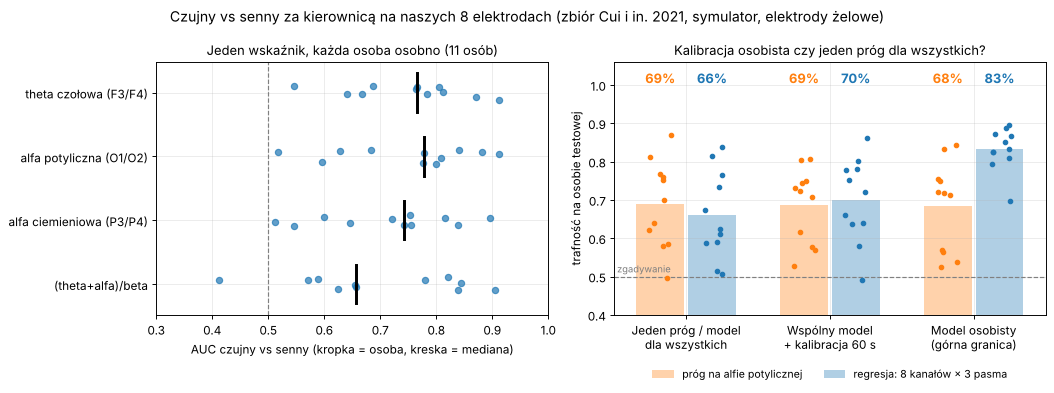

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw=dict(width_ratios=[1, 1.1]))
show = [m for m in summary["mean"].sort_values().index if m != "b_ta"]     # b_ta = 1 / ta_b, same AUC
for k, mk in enumerate(show):
    v = auc[mk].values
    a1.scatter(v, np.full(len(v), k) + rng.uniform(-0.12, 0.12, len(v)), s=28, color="tab:blue", alpha=0.7, zorder=3)
    a1.plot([np.median(v)] * 2, [k - 0.3, k + 0.3], color="black", lw=2.5, zorder=4)
a1.axvline(0.5, color="gray", ls="--", lw=1)
a1.set_yticks(range(len(show)))
a1.set_yticklabels([MARKER_PL[m] for m in show])
a1.set_xlim(0.3, 1.0)
a1.set_xlabel("AUC czujny vs senny (kropka = osoba, kreska = mediana)")
a1.set_title("Jeden wskaźnik, każda osoba osobno (11 osób)", fontsize=11)

groups = [("Jeden próg / model\ndla wszystkich", res_A), ("Wspólny model\n+ kalibracja 60 s", res_B1),
          ("Model osobisty\n(górna granica)", res_Cb)]
kinds = [("thr_alpha_occ", "próg na alfie potylicznej", "tab:orange"), ("lr_bacc", "regresja: 8 kanałów × 3 pasma", "tab:blue")]
w = 0.36
for k, (lab, res) in enumerate(groups):
    for j, (col, klab, c) in enumerate(kinds):
        x0 = k + (j - 0.5) * w
        v = res[col]
        a2.bar(x0, v.mean(), width=w * 0.92, color=c, alpha=0.35, label=klab if k == 0 else None)
        a2.scatter(np.full(len(v), x0) + rng.uniform(-0.08, 0.08, len(v)), v, color=c, s=14, zorder=3)
        a2.text(x0, 1.005, f"{v.mean():.0%}", ha="center", fontsize=11, fontweight="bold", color=c)
a2.axhline(0.5, color="gray", ls="--", lw=1)
a2.text(-0.48, 0.505, "zgadywanie", fontsize=8, color="gray", ha="left", va="bottom")
a2.set_xticks(range(len(groups)))
a2.set_xticklabels([g[0] for g in groups])
a2.set_ylim(0.4, 1.06)
a2.set_xlim(-0.5, 2.5)
a2.set_ylabel("trafność na osobie testowej")
a2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9, frameon=False)
a2.set_title("Kalibracja osobista czy jeden próg dla wszystkich?", fontsize=11)
fig.suptitle("Czujny vs senny za kierownicą na naszych 8 elektrodach (zbiór Cui i in. 2021, symulator, elektrody żelowe)",
             fontsize=12)
fig.tight_layout()

img_dir = Path("../../docs/img") if Path("../../docs").exists() else Path(".")
img_dir.mkdir(exist_ok=True)
out = img_dir / "drowsiness-public-auc-and-calibration.png"
fig.savefig(out, dpi=110, bbox_inches="tight")
print(out.resolve(), f"{out.stat().st_size / 1e3:.0f} kB")
plt.show()

## 7. Wnioski

Wszystkie liczby pochodzą z wykonanych komórek powyżej (sekcje 1–5).

**Zbiór.** 11 osób, 2022 okna po 3 s przy 128 Hz, 30 kanałów żelowych z referencją na wyrostkach sutkowatych, licencja CC BY 4.0. Wszystkie nasze kanały (F3, F4, C3, C4, P3, P4, O1, O2) są w zbiorze. Po regule 300 µV odpadło 25 z 2022 okien.

**1. Na naszych 8 elektrodach senność widać, ale tylko umiarkowanie.**
- Alfa potyliczna (O1/O2): średnie AUC na osobę 0,75, zakres 0,52–0,91. Kierunek zgodny z oczekiwanym u 11 z 11 osób, AUC ≥ 0,7 u 7 z 11.
- Theta czołowa (F3/F4) ma praktycznie to samo średnie AUC (0,75, zakres 0,55–0,91). Alfa ciemieniowa: 0,71 (0,51–0,90).
- (theta+alfa)/beta: 0,70 (0,41–0,90), a u jednej osoby kierunek jest odwrotny. beta/(alfa+theta) to dokładna odwrotność tego stosunku, więc niesie tę samą informację.

**2. Kalibracja osobista czy jeden próg dla wszystkich?**

| Strategia | Próg na alfie O1/O2 | Regresja (24 cechy): trafność | Regresja: AUC |
|---|---|---|---|
| A. jeden model/próg dla wszystkich, bez normalizacji | 0,69 | 0,66 | 0,76 |
| B1. wspólny model + kalibracja z 60 s okien czujnych | 0,69 | 0,70 | 0,76 |
| B2. wspólny model + z-score bez etykiet (optymistyczny) | 0,70 | 0,72 | 0,77 |
| C'. model osobisty, foldy blokowe (górna granica) | 0,68 | 0,83 | 0,90 |

- **Dla pojedynczego wskaźnika kalibracja nic nie daje**: próg na alfie potylicznej ma ok. 69% trafności w każdej strategii, także gdy próg jest dobrany na tej samej osobie. Ograniczeniem jest nakładanie się okien czujnych i sennych u jednej osoby, a nie przesunięcie poziomu między osobami. To nie znaczy, że poziomy są podobne: poziom alfy w stanie czujnym różni się między osobami (SD 0,34 log10, przy średniej zmianie stanu 0,51), a u 5 z 11 osób poziom „czujny” jest wyższy niż poziom „senny” innej osoby.
- **Dla modelu wielocechowego 60 s kalibracji pomaga trochę**: trafność 0,66 → 0,70 (lepiej u 8 z 11 osób), AUC bez zmian (0,76).
- **Duży skok daje dopiero model osobisty** (0,83 trafności, AUC 0,90), ale wymaga on etykiet senności od tej samej osoby. Krótka kalibracja na wypoczętej osobie tego nie zastępuje. Foldy losowe dają niemal to samo (0,85), więc przeciek między sąsiednimi oknami nie wygląda na duży, o ile kolejność w pliku coś mówi o czasie (nie wiemy tego).

**3. Referencja Fp1 (nasz sprzęt).** Alfa potyliczna się trzyma (średnie AUC 0,75, kierunek zgodny u 11 z 11 osób). **Theta czołowa się rozpada** (średnie AUC 0,58, od 0,19 do 0,87, kierunek zgodny tylko u 8 z 11), bo F3/F4 leżą tuż obok referencji. Na naszym sprzęcie theta czołowa nie nadaje się na główny wskaźnik, nawet jeśli w zbiorze laboratoryjnym wygląda dobrze.

**Co to znaczy dla Wachty.**
- To dobry argument za alfą potyliczną jako rdzeniem wskaźnika i dowód, że zmiana czujny/senny jest widoczna na naszym układzie 8 elektrod. Na slajd: „alfa potyliczna rośnie przy senności u 11 z 11 osób, AUC 0,75 (0,52–0,91)”.
- Ten zbiór **nie potwierdza**, że 60 s kalibracji (z-score) wyraźnie poprawia wykrywanie senności. Zysk jest mały (+4 pkt proc. tylko dla modelu wielocechowego). Uczciwy przekaz: „personalizacja jest potrzebna, ale prawdziwy zysk wymaga uczenia na danych tej osoby, nie tylko 60 s spoczynku”. To pasuje do planu „model osobisty uczony z EEG” po hackathonie, nie do twierdzenia, że sama kalibracja wystarcza.

**Ograniczenia.**
- Elektrody żelowe Ag/AgCl w laboratorium, 30 kanałów, referencja na wyrostkach sutkowatych. Nasz sprzęt to suche elektrody i referencja Fp1, a wariant Fp1 w sekcji 5 to tylko przybliżenie: Fp1 jest tu już oczyszczone z mrugnięć.
- Autorzy zbioru Cao i in. usunęli artefakty (ręcznie mrugnięcia, AAR dla oczu i mięśni) i przefiltrowali sygnał 1–50 Hz; nasze dane są surowe.
- Symulator jazdy, 90 min po obiedzie, studenci i pracownicy uczelni w wieku 22–28 lat. To nie praca zmianowa.
- Etykieta to **czas reakcji** na zjazd z pasa (lokalny i z 90 s) względem najlepszych reakcji tej osoby, a nie EEG ani samoocena. Okno to 3 s tuż przed zjazdem.
- Autorzy **zrównoważyli klasy, wybierając skrajne okna** (najszybsze reakcje jako czujne, najwolniejsze jako senne), a stany pośrednie wyrzucili. To zawyża rozdzielność względem płynnej zmiany w realnej pracy. Wybrali też 11 z 27 osób (sesje z ≥ 50 oknami każdej klasy).
- Okna czujne i senne pochodzą zwykle z różnych części sesji, więc etykieta jest pomieszana z czasem jazdy i dryfem elektrod. W pliku nie ma znaczników czasu.
- Okna mają 3 s, a nasz pipeline używa 2 s. Moc liczymy z dwóch segmentów 2 s w każdym oknie.
- Kalibracja w B1 bierze losowe okna czujne z całej sesji, co jest łagodniejsze niż kalibracja tylko na starcie zmiany.
- 11 osób to mało. Różnice rzędu 1–2 pkt proc. między strategiami są w granicach szumu.